# Notebook 8 — Final Comparative Evaluation

## Aim

This notebook consolidates the outputs from Notebooks 4–7 and answers the dissertation research question:

> **To what extent does Knowledge Graph refinement through entity canonicalisation improve graph representation learning and downstream cyber entity classification?**

No model is retrained here. The notebook:

- validates that all required experiment outputs exist;
- compares Majority Class, Logistic Regression, Random Forest and GraphSAGE;
- compares full-graph and connected-node performance;
- compares the original and canonical graph pipelines;
- performs paired statistical tests across the same ten seeds;
- quantifies absolute and relative improvements;
- produces dissertation-ready tables and figures;
- records limitations and an evidence-based answer to the research question.

## 1. Imports and reproducibility

In [56]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scipy.stats import wilcoxon

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda value: f"{value:.4f}")

print("Libraries loaded successfully.")
print("Random seed:", SEED)

Libraries loaded successfully.
Random seed: 42


## 2. Project paths

The notebook assumes it is stored inside the project `notebooks` folder. It searches the existing output structure used in Notebooks 4–7.

In [57]:
PROJECT_ROOT= Path.cwd().resolve().parent
OUTPUT_ROOT= PROJECT_ROOT / "outputs"

GRAPHSAGE_DIR= OUTPUT_ROOT / "graphsage_final"
ML_BASELINE_DIR= OUTPUT_ROOT / "ml_baseline"
NODE2VEC_DIR= OUTPUT_ROOT / "node2vec_embeddings"

FINAL_EVALUATION_DIR = OUTPUT_ROOT / "final_evaluation"
FINAL_FIGURE_DIR = FINAL_EVALUATION_DIR / "figures"
FINAL_TABLE_DIR = FINAL_EVALUATION_DIR / "tables"

for directory in [
    FINAL_EVALUATION_DIR,
    FINAL_FIGURE_DIR,
    FINAL_TABLE_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Output root:", OUTPUT_ROOT)
print("GraphSAGE outputs:", GRAPHSAGE_DIR)
print("Final evaluation outputs:", FINAL_EVALUATION_DIR)

Project root: E:\Subjects\cti-graph-project
Output root: E:\Subjects\cti-graph-project\outputs
GraphSAGE outputs: E:\Subjects\cti-graph-project\outputs\graphsage_final
Final evaluation outputs: E:\Subjects\cti-graph-project\outputs\final_evaluation


## 3. File validation and safe loaders

In [58]:
def require_file(path: Path) -> Path:
    if not path.exists():
        raise FileNotFoundError(
            f"Required file not found: {path}\n"
            "Run the relevant earlier notebook before continuing.")
    return path


def read_required_csv(path: Path) -> pd.DataFrame:
    return pd.read_csv(require_file(path))


def read_optional_csv(path: Path) -> pd.DataFrame | None:
    if path.exists():
        return pd.read_csv(path)

    print("Optional file not found:", path.name)
    return None


required_graphsage_files = {
    "full_model_comparison": GRAPHSAGE_DIR / "full_graph_model_comparison.csv",
    "connected_model_comparison": GRAPHSAGE_DIR / "connected_model_comparison.csv",
    "full_graphsage_runs": GRAPHSAGE_DIR / "full_graph_graphsage_seed_results.csv",
    "connected_graphsage_runs": GRAPHSAGE_DIR / "connected_graphsage_seed_results.csv",
    "full_baseline_runs": GRAPHSAGE_DIR / "full_graph_baseline_seed_results.csv",
    "connected_baseline_runs": GRAPHSAGE_DIR / "connected_baseline_seed_results.csv",
    "original_vs_canonical_runs": GRAPHSAGE_DIR / "original_vs_canonical_seed_results.csv",
    "original_vs_canonical_summary": GRAPHSAGE_DIR / "original_vs_canonical_summary.csv",
    "graphsage_summary": GRAPHSAGE_DIR / "graphsage_summary_mean_std.csv",
    "connectivity_validation": GRAPHSAGE_DIR / "connectivity_validation.csv",
    "canonical_edge_diagnostics": GRAPHSAGE_DIR / "canonical_edge_diagnostics.csv",
    "counterfactual_edge_diagnostics": GRAPHSAGE_DIR / "counterfactual_edge_retention_diagnostics.csv",
    "hyperparameter_tuning": GRAPHSAGE_DIR / "graphsage_hyperparameter_tuning.csv",
    "confidence_summary": GRAPHSAGE_DIR / "prediction_confidence_summary.csv",
    "error_summary": GRAPHSAGE_DIR / "representative_error_summary.csv",
    "experiment_configuration": GRAPHSAGE_DIR / "final_experiment_configuration.json"
}

missing_files = [
    str(path)
    for path in required_graphsage_files.values()
    if not path.exists()]

if missing_files:
    raise FileNotFoundError(
        "Notebook 8 cannot continue because these Notebook 7 outputs are missing:\n"
        + "\n".join(missing_files))

print("All required Notebook 7 outputs are available.")

All required Notebook 7 outputs are available.


## 4. Load final experimental results

In [59]:
full_model_comparison_df = read_required_csv(required_graphsage_files["full_model_comparison"])

connected_model_comparison_df = read_required_csv(required_graphsage_files["connected_model_comparison"])

full_graphsage_runs_df = read_required_csv(required_graphsage_files["full_graphsage_runs"])

connected_graphsage_runs_df = read_required_csv(required_graphsage_files["connected_graphsage_runs"])

full_baseline_runs_df = read_required_csv(required_graphsage_files["full_baseline_runs"])

connected_baseline_runs_df = read_required_csv(required_graphsage_files["connected_baseline_runs"])

original_vs_canonical_runs_df = read_required_csv(required_graphsage_files["original_vs_canonical_runs"])

original_vs_canonical_summary_df = read_required_csv(required_graphsage_files["original_vs_canonical_summary"])

graphsage_summary_df = read_required_csv(required_graphsage_files["graphsage_summary"])

connectivity_validation_df = read_required_csv(required_graphsage_files["connectivity_validation"])

canonical_edge_diagnostics_df = read_required_csv(required_graphsage_files["canonical_edge_diagnostics"])

counterfactual_edge_diagnostics_df = read_required_csv(required_graphsage_files["counterfactual_edge_diagnostics"])

hyperparameter_tuning_df = read_required_csv(
    required_graphsage_files["hyperparameter_tuning"]
)

confidence_summary_df = read_required_csv(required_graphsage_files["confidence_summary"])

error_summary_df = read_required_csv(required_graphsage_files["error_summary"])

with open(
    required_graphsage_files["experiment_configuration"],
    "r",
    encoding="utf-8"
) as file:
    experiment_configuration = json.load(file)

print("Final experiment outputs loaded successfully.")
print("Evaluation seeds:", experiment_configuration["evaluation_seeds"])
print("Primary metric:", experiment_configuration["primary_metric"])

Final experiment outputs loaded successfully.
Evaluation seeds: [11, 22, 33, 42, 55, 66, 77, 88, 99, 111]
Primary metric: macro_f1


## 5. Graph refinement Evidence

These files add graph-refinement and Node2Vec context when present. Their absence does not stop the final predictive comparison.

In [60]:
#Collects evidence showing how canonicalisation changed the graph
graph_refinement_file = (OUTPUT_ROOT/ "graph_original_vs_canonical_v1_v2_v3_v4_comparison.csv")

node2vec_training_file = (NODE2VEC_DIR/ "node2vec_training_summary.csv")

node2vec_quality_file = (NODE2VEC_DIR/ "node2vec_embedding_quality_summary.csv")

graph_refinement_df = read_optional_csv(graph_refinement_file)

node2vec_training_df = read_optional_csv(node2vec_training_file)

node2vec_quality_df = read_optional_csv(node2vec_quality_file)

if graph_refinement_df is not None:
    display(graph_refinement_df)

if node2vec_training_df is not None:
    display(node2vec_training_df)

,graph_version,nodes,edges,density,weakly_connected_components
0,Original mention-level graph,12679,1094,0.0000,11672
1,V1 - exact normalised match,4385,945,0.0000,3571
2,V2 - noise filtered,4363,935,0.0000,3557
3,V3 - punctuation-insensitive,4354,933,0.0000,3550
4,V4 - fuzzy matched,4050,910,0.0001,3267


,graph_version,num_nodes,num_edges,embedding_dim,walk_length,context_size,walks_per_node,p,q,batch_size,learning_rate,epochs,seed,final_loss,training_time_seconds,link_prediction_auc,link_prediction_ap
0,canonical_v4_final,4050,910,128,20,10,10,1.0000,1.0000,128,0.0100,50,42,0.7234,717.2440,0.9934,0.9929


## 6. Experimental protocol summary

In [61]:
protocol_summary_df = pd.DataFrame([{
    "task": experiment_configuration["task"],
    "feature_type": experiment_configuration["feature_type"],
    "normalisation": experiment_configuration["normalisation"],
    "direction_handling": experiment_configuration["direction_handling"],
    "primary_metric": experiment_configuration["primary_metric"],
    "evaluation_seed_count": len(
        experiment_configuration["evaluation_seeds"]
    ),
    "full_graph_split": experiment_configuration["full_graph_split"],
    "selected_hidden_dim": experiment_configuration[
        "selected_configuration"
    ]["hidden_dim"],
    "selected_dropout": experiment_configuration[
        "selected_configuration"
    ]["dropout"],
    "selected_learning_rate": experiment_configuration[
        "selected_configuration"
    ]["learning_rate"]
}])

display(protocol_summary_df)

,task,feature_type,normalisation,direction_handling,primary_metric,evaluation_seed_count,full_graph_split,selected_hidden_dim,selected_dropout,selected_learning_rate
0,transductive_multiclass_node_classification,128-dimensional Node2Vec,LayerNorm,separate incoming and outgoing aggregation,macro_f1,10,Notebook 6 fixed split,64,0.3000,0.0050


## 7. Graph refinement and connectivity evidence

In [62]:
#Examines how refinement affected graph structure and connectivity
connectivity_row = connectivity_validation_df.iloc[0]

connectivity_summary_df = pd.DataFrame([{
    "total_canonical_nodes": int(
        connectivity_row["connected_from_model_edge_index"]
        + (
            connectivity_row["isolated_test_nodes"]
            / connectivity_row["test_nodes"]
        ) * 0  # retained only to keep formula explicit
    ) if False else 4050,
    "connected_canonical_nodes": int(
        connectivity_row["connected_from_model_edge_index"]),
    "test_nodes": int(connectivity_row["test_nodes"]),
    "connected_test_nodes": int(
        connectivity_row["connected_test_nodes"]),
    "isolated_test_nodes": int(
        connectivity_row["isolated_test_nodes"]),
    "isolated_test_percentage": float(
        connectivity_row["isolated_test_percentage"]),
    "connectivity_definition_mismatches": int(
        connectivity_row["connectivity_definition_mismatches"] )}])

# Use graph diagnostic node counts when available.
if "total_graph_nodes" in counterfactual_edge_diagnostics_df.columns:
    canonical_rows = counterfactual_edge_diagnostics_df[
        counterfactual_edge_diagnostics_df["condition"].str.contains(
            "canonical",
            case=False,
            na=False)]
    if not canonical_rows.empty:
        connectivity_summary_df.loc[
            0,
            "total_canonical_nodes"] = int(canonical_rows.iloc[0]["total_graph_nodes"])

display(connectivity_summary_df)
display(canonical_edge_diagnostics_df)
display(counterfactual_edge_diagnostics_df)

,total_canonical_nodes,connected_canonical_nodes,test_nodes,connected_test_nodes,isolated_test_nodes,isolated_test_percentage,connectivity_definition_mismatches
0,4050,903,608,132,476,78.2895,0


,condition,total_graph_edges,mapped_edges_before_cleaning,dropped_edges_unmapped_endpoint,self_loops_removed,unique_directed_edges_retained,edge_retention_percentage
0,canonical_graph,910,910,0,0,910,100.0000


,condition,total_graph_edges,mapped_edges_before_cleaning,dropped_edges_unmapped_endpoint,self_loops_removed,unique_directed_edges_retained,edge_retention_percentage,total_graph_nodes,labelled_nodes_retained,unlabelled_or_unrecognised_nodes_excluded,connected_labelled_nodes
0,original_graph,1094,1094,0,0,1094,100.0000,12679,12679,0,1533
1,canonical_graph_counterfactual,910,910,0,0,910,100.0000,4050,4050,0,903


### Interpretation

The full-graph result must be interpreted together with the isolated-node rate. GraphSAGE can aggregate neighbourhood information only where graph edges exist. The connected-node evaluation therefore isolates the setting in which graph-aware learning can operate as intended.

## 8. Final full-graph model comparison

In [63]:
#Compares ML baselines and GraphSAGE on the full graph
full_display_columns = [
    "model",
    "accuracy_mean",
    "accuracy_std",
    "balanced_accuracy_mean",
    "macro_f1_mean",
    "macro_f1_std",
    "weighted_f1_mean",
    "mcc_mean",
    "macro_roc_auc_present_classes_mean"
]

full_comparison_table_df = (
    full_model_comparison_df[
        full_display_columns
    ]
    .sort_values(
        "macro_f1_mean",
        ascending=False
    )
    .reset_index(drop=True)
)

display(full_comparison_table_df)

,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,macro_f1_mean,macro_f1_std,weighted_f1_mean,mcc_mean,macro_roc_auc_present_classes_mean
0,GraphSAGE,0.1548,0.0088,0.1102,0.1108,0.0091,0.1555,0.0849,0.5932
1,Random Forest,0.1268,0.0102,0.0649,0.0520,0.0053,0.0960,0.0303,0.5391
2,Logistic Regression,0.0576,0.0000,0.0763,0.0497,0.0000,0.0649,0.0124,0.5201
3,Majority Class,0.1086,0.0000,0.0500,0.0098,0.0000,0.0213,0.0000,0.5000


## 9. Connected-node model comparison

In [64]:
#Compares models using only nodes that have graph connections
connected_display_columns = [
    "model",
    "accuracy_mean",
    "accuracy_std",
    "balanced_accuracy_mean",
    "macro_f1_mean",
    "macro_f1_std",
    "weighted_f1_mean",
    "mcc_mean",
    "macro_roc_auc_present_classes_mean"
]

connected_comparison_table_df = (
    connected_model_comparison_df[
        connected_display_columns
    ]
    .sort_values(
        "macro_f1_mean",
        ascending=False
    )
    .reset_index(drop=True)
)

display(connected_comparison_table_df)

,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,macro_f1_mean,macro_f1_std,weighted_f1_mean,mcc_mean,macro_roc_auc_present_classes_mean
0,GraphSAGE,0.3900,0.0178,0.3327,0.3212,0.0326,0.3915,0.3204,0.7929
1,Logistic Regression,0.1846,0.0000,0.1609,0.1428,0.0000,0.1662,0.1182,0.6922
2,Random Forest,0.3015,0.0153,0.1460,0.1324,0.0124,0.2365,0.1705,0.7354
3,Majority Class,0.2385,0.0000,0.0667,0.0257,0.0000,0.0918,0.0000,0.5000


## 10. Full graph versus connected graph

This comparison measures how strongly sparse connectivity dilutes GraphSAGE performance.

In [65]:
#Checks whether connected nodes perform better than the whole graph
graphsage_condition_comparison_df = (
    graphsage_summary_df[
        [
            "experiment",
            "runs",
            "accuracy_mean",
            "accuracy_std",
            "macro_f1_mean",
            "macro_f1_std",
            "mcc_mean",
            "mcc_std",
            "macro_roc_auc_present_classes_mean",
            "macro_roc_auc_present_classes_std"
        ]
    ]
    .copy()
)

display(graphsage_condition_comparison_df)

full_graph_macro_f1 = float(
    graphsage_condition_comparison_df.loc[
        graphsage_condition_comparison_df[
            "experiment"
        ].str.contains("full", case=False),
        "macro_f1_mean"
    ].iloc[0]
)

connected_macro_f1 = float(
    graphsage_condition_comparison_df.loc[
        graphsage_condition_comparison_df[
            "experiment"
        ].str.contains("connected", case=False),
        "macro_f1_mean"
    ].iloc[0]
)

connected_gain = (
    connected_macro_f1
    - full_graph_macro_f1
)

connected_relative_gain = (
    100
    * connected_gain
    / max(full_graph_macro_f1, 1e-12)
)

print("Connected-node macro-F1 gain:", round(connected_gain, 4))
print("Relative gain over full graph:", round(connected_relative_gain, 2), "%")

,experiment,runs,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,mcc_mean,mcc_std,macro_roc_auc_present_classes_mean,macro_roc_auc_present_classes_std
0,Canonical full graph,10,0.1548,0.0088,0.1108,0.0091,0.0849,0.0100,0.5932,0.0186
1,Canonical connected eligible,10,0.3900,0.0178,0.3212,0.0326,0.3204,0.0185,0.7929,0.0265


Connected-node macro-F1 gain: 0.2103
Relative gain over full graph: 189.77 %


## 11. Original graph versus canonical graph

This pipeline-level counterfactual directly addresses the research question. Both graph conditions use identical Node2Vec and GraphSAGE settings, while acknowledging that canonicalisation changes the node population.

In [66]:
#Tests whether canonicalisation improved GraphSAGE performance
counterfactual_table_df = (
    original_vs_canonical_summary_df[
        [
            "experiment",
            "runs",
            "accuracy_mean",
            "accuracy_std",
            "macro_f1_mean",
            "macro_f1_std",
            "weighted_f1_mean",
            "mcc_mean",
            "mcc_std",
            "macro_roc_auc_present_classes_mean",
            "macro_roc_auc_present_classes_std"
        ]
    ]
    .copy()
)

display(counterfactual_table_df)

original_macro_f1 = float(
    counterfactual_table_df.loc[
        counterfactual_table_df[
            "experiment"
        ].str.contains("Original", case=False),
        "macro_f1_mean"
    ].iloc[0]
)

canonical_macro_f1 = float(
    counterfactual_table_df.loc[
        counterfactual_table_df[
            "experiment"
        ].str.contains("Canonical", case=False),
        "macro_f1_mean"
    ].iloc[0]
)

canonical_absolute_gain = (
    canonical_macro_f1
    - original_macro_f1
)

canonical_relative_gain = (
    100
    * canonical_absolute_gain
    / max(original_macro_f1, 1e-12)
)

print("Canonical macro-F1 gain:", round(canonical_absolute_gain, 4))
print("Relative gain over original graph:", round(canonical_relative_gain, 2), "%")

,experiment,runs,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,mcc_mean,mcc_std,macro_roc_auc_present_classes_mean,macro_roc_auc_present_classes_std
0,Original graph counterfactual,10,0.2696,0.0169,0.1792,0.0147,0.2515,0.1501,0.0193,0.6616,0.0204
1,Canonical graph counterfactual,10,0.3700,0.0317,0.3248,0.0335,0.3667,0.2972,0.0356,0.7510,0.0288


Canonical macro-F1 gain: 0.1457
Relative gain over original graph: 81.31 %


## 12. Paired statistical tests

The same seeds were used across paired conditions. A two-sided Wilcoxon signed-rank test is therefore applied to the per-seed macro-F1 differences.

The test does not replace effect-size reporting. Mean differences and the number of winning seeds are reported alongside the p-value.

In [67]:
#Checks whether performance differences are statistically meaningful
def paired_wilcoxon_summary(
    left_df: pd.DataFrame,
    right_df: pd.DataFrame,
    left_name: str,
    right_name: str,
    metric: str = "macro_f1"
) -> dict:
    paired = (
        left_df[["seed", metric]]
        .rename(columns={metric: "left_metric"})
        .merge(
            right_df[["seed", metric]].rename(
                columns={metric: "right_metric"}
            ),
            on="seed",
            how="inner"
        )
        .sort_values("seed"))

    if paired.empty:
        raise ValueError(
            f"No matched seeds for {left_name} and {right_name}.")

    differences = (
        paired["left_metric"]
        - paired["right_metric"])

    statistic, p_value = wilcoxon(
        paired["left_metric"],
        paired["right_metric"],
        alternative="two-sided",
        zero_method="wilcox")

    return {
        "comparison": f"{left_name} vs {right_name}",
        "metric": metric,
        "paired_seeds": int(len(paired)),
        "left_mean": float(paired["left_metric"].mean()),
        "right_mean": float(paired["right_metric"].mean()),
        "mean_difference": float(differences.mean()),
        "median_difference": float(differences.median()),
        "left_wins": int((differences > 0).sum()),
        "ties": int((differences == 0).sum()),
        "right_wins": int((differences < 0).sum()),
        "wilcoxon_statistic": float(statistic),
        "p_value": float(p_value)}


full_rf_runs_df = full_baseline_runs_df[
    full_baseline_runs_df["model"].eq("Random Forest")
].copy()

connected_rf_runs_df = connected_baseline_runs_df[
    connected_baseline_runs_df["model"].eq("Random Forest")
].copy()

original_runs_df = original_vs_canonical_runs_df[
    original_vs_canonical_runs_df[
        "experiment"
    ].str.contains("original", case=False)
].copy()

canonical_runs_df = original_vs_canonical_runs_df[
    original_vs_canonical_runs_df[
        "experiment"
    ].str.contains("canonical", case=False)
].copy()

statistical_tests_df = pd.DataFrame([
    paired_wilcoxon_summary(
        full_graphsage_runs_df,
        full_rf_runs_df,
        "GraphSAGE full graph",
        "Random Forest full graph"
    ),
    paired_wilcoxon_summary(
        connected_graphsage_runs_df,
        connected_rf_runs_df,
        "GraphSAGE connected",
        "Random Forest connected"
    ),
    paired_wilcoxon_summary(
        canonical_runs_df,
        original_runs_df,
        "Canonical graph",
        "Original graph")])

display(statistical_tests_df)

,comparison,metric,paired_seeds,left_mean,right_mean,mean_difference,median_difference,left_wins,ties,right_wins,wilcoxon_statistic,p_value
0,GraphSAGE full graph vs Random Forest full graph,macro_f1,10,0.1108,0.0520,0.0588,0.0634,10,0,0,0.0000,0.0020
1,GraphSAGE connected vs Random Forest connected,macro_f1,10,0.3212,0.1324,0.1887,0.1877,10,0,0,0.0000,0.0020
2,Canonical graph vs Original graph,macro_f1,10,0.3248,0.1792,0.1457,0.1485,10,0,0,0.0000,0.0020


## 13. Effect-size summary

In [68]:
#Measures how large the observed performance differences actually are
def get_model_row(
    comparison_df: pd.DataFrame,
    model_name: str
) -> pd.Series:
    rows = comparison_df[
        comparison_df["model"].eq(model_name)
    ]

    if rows.empty:
        raise ValueError(
            f"Model not found: {model_name}"
        )

    return rows.iloc[0]


full_graphsage_row = get_model_row(
    full_model_comparison_df,
    "GraphSAGE"
)

full_rf_row = get_model_row(
    full_model_comparison_df,
    "Random Forest"
)

connected_graphsage_row = get_model_row(
    connected_model_comparison_df,
    "GraphSAGE"
)

connected_rf_row = get_model_row(
    connected_model_comparison_df,
    "Random Forest"
)

effect_size_summary_df = pd.DataFrame([
    {
        "comparison": "GraphSAGE minus Random Forest — full graph",
        "macro_f1_absolute_gain": (
            full_graphsage_row["macro_f1_mean"]
            - full_rf_row["macro_f1_mean"]),
        "macro_f1_relative_gain_percent": (
            100
            * (
                full_graphsage_row["macro_f1_mean"]
                - full_rf_row["macro_f1_mean"]
            ) / max(full_rf_row["macro_f1_mean"], 1e-12)),
        "accuracy_absolute_gain": (
            full_graphsage_row["accuracy_mean"]
            - full_rf_row["accuracy_mean"]),
        "mcc_absolute_gain": (
            full_graphsage_row["mcc_mean"]
            - full_rf_row["mcc_mean"])},
    {
        "comparison": "GraphSAGE minus Random Forest — connected",
        "macro_f1_absolute_gain": (
            connected_graphsage_row["macro_f1_mean"]
            - connected_rf_row["macro_f1_mean"]),
        "macro_f1_relative_gain_percent": (
            100
            * (
                connected_graphsage_row["macro_f1_mean"]
                - connected_rf_row["macro_f1_mean"])/ max(connected_rf_row["macro_f1_mean"], 1e-12)),
        "accuracy_absolute_gain": (
            connected_graphsage_row["accuracy_mean"]
            - connected_rf_row["accuracy_mean"]
        ),
        "mcc_absolute_gain": (
            connected_graphsage_row["mcc_mean"]
            - connected_rf_row["mcc_mean"])},
    {
        "comparison": "Canonical minus original graph",
        "macro_f1_absolute_gain": canonical_absolute_gain,
        "macro_f1_relative_gain_percent": canonical_relative_gain,
        "accuracy_absolute_gain": (
            counterfactual_table_df.loc[
                counterfactual_table_df[
                    "experiment"
                ].str.contains("Canonical", case=False),
                "accuracy_mean"
            ].iloc[0]
            - counterfactual_table_df.loc[
                counterfactual_table_df[
                    "experiment"
                ].str.contains("Original", case=False),
                "accuracy_mean"
            ].iloc[0]
        ),
        "mcc_absolute_gain": (
            counterfactual_table_df.loc[
                counterfactual_table_df[
                    "experiment"
                ].str.contains("Canonical", case=False),
                "mcc_mean"
            ].iloc[0]
            - counterfactual_table_df.loc[
                counterfactual_table_df[
                    "experiment"
                ].str.contains("Original", case=False),
                "mcc_mean"
            ].iloc[0])}])
display(effect_size_summary_df)

,comparison,macro_f1_absolute_gain,macro_f1_relative_gain_percent,accuracy_absolute_gain,mcc_absolute_gain
0,GraphSAGE minus Random Forest — full graph,0.0588,113.0454,0.0280,0.0546
1,GraphSAGE minus Random Forest — connected,0.1887,142.5375,0.0885,0.1499
2,Canonical minus original graph,0.1457,81.3129,0.1004,0.1471


## 14. Dissertation-ready visualisations

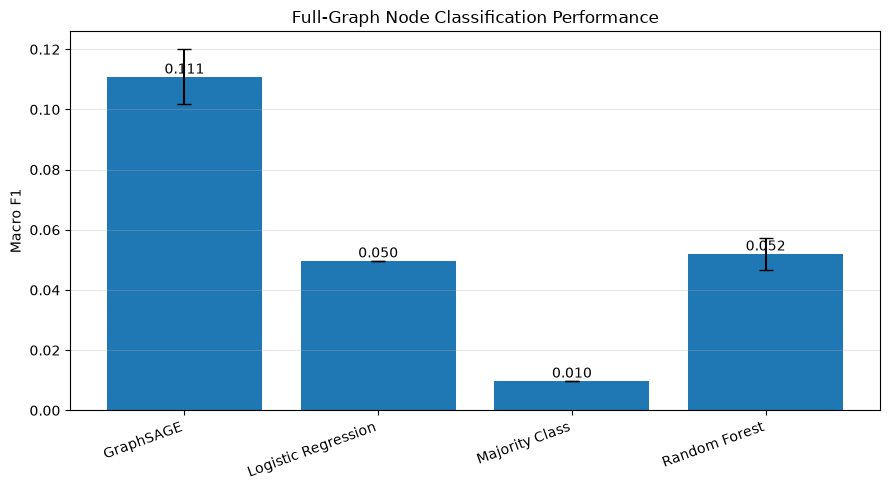

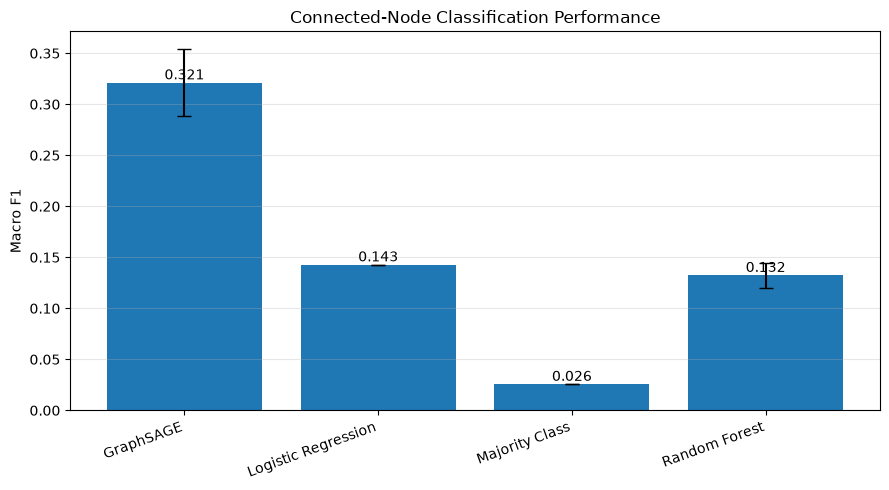

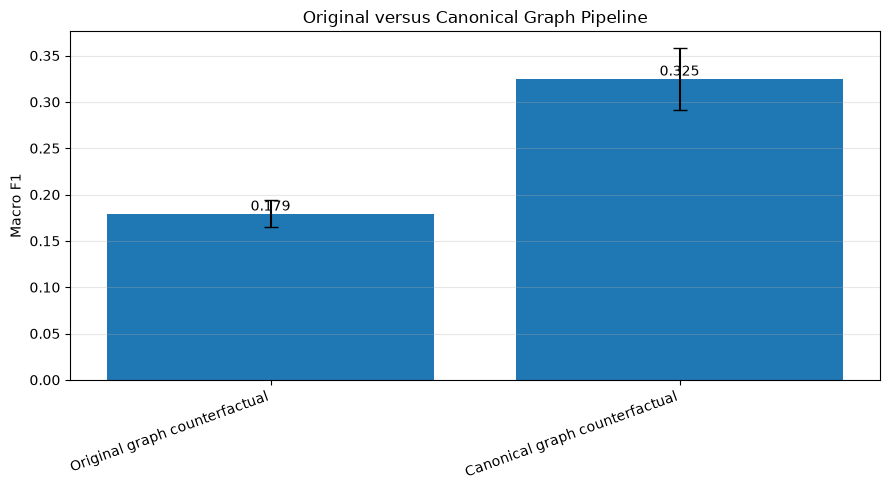

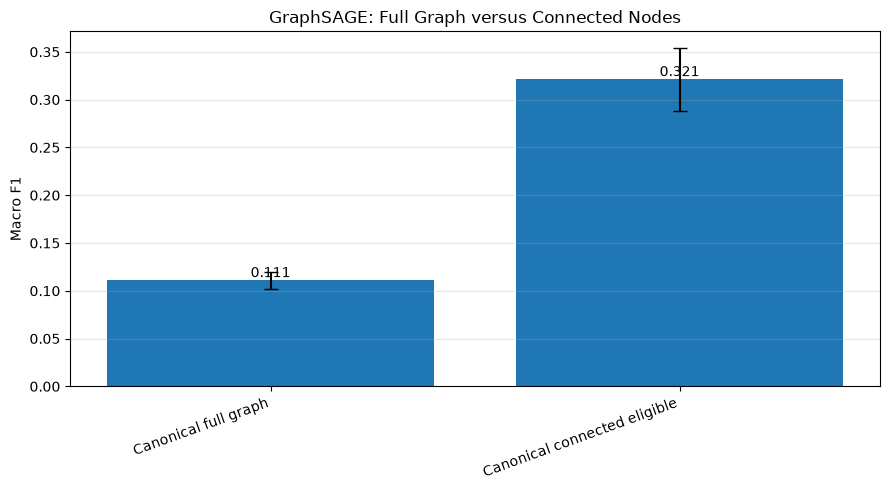

Figures saved to: E:\Subjects\cti-graph-project\outputs\final_evaluation\figures


In [69]:
#Creates final graphs/figures for the dissertation
def save_bar_chart(
    labels,
    values,
    errors,
    title,
    ylabel,
    filename
):
    fig, ax = plt.subplots(figsize=(9, 5))

    positions = np.arange(len(labels))

    ax.bar(
        positions,
        values,
        yerr=errors,
        capsize=5
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(labels, rotation=20, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)

    for position, value in zip(positions, values):
        ax.text(
            position,
            value,
            f"{value:.3f}",
            ha="center",
            va="bottom"
        )

    fig.tight_layout()

    figure_path = FINAL_FIGURE_DIR / filename
    fig.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    return figure_path


full_chart_path = save_bar_chart(
    labels=full_model_comparison_df["model"].tolist(),
    values=full_model_comparison_df["macro_f1_mean"].tolist(),
    errors=full_model_comparison_df["macro_f1_std"].tolist(),
    title="Full-Graph Node Classification Performance",
    ylabel="Macro F1",
    filename="full_graph_model_macro_f1.png"
)

connected_chart_path = save_bar_chart(
    labels=connected_model_comparison_df["model"].tolist(),
    values=connected_model_comparison_df["macro_f1_mean"].tolist(),
    errors=connected_model_comparison_df["macro_f1_std"].tolist(),
    title="Connected-Node Classification Performance",
    ylabel="Macro F1",
    filename="connected_model_macro_f1.png"
)

counterfactual_chart_path = save_bar_chart(
    labels=counterfactual_table_df["experiment"].tolist(),
    values=counterfactual_table_df["macro_f1_mean"].tolist(),
    errors=counterfactual_table_df["macro_f1_std"].tolist(),
    title="Original versus Canonical Graph Pipeline",
    ylabel="Macro F1",
    filename="original_vs_canonical_macro_f1.png"
)

condition_chart_path = save_bar_chart(
    labels=graphsage_condition_comparison_df["experiment"].tolist(),
    values=graphsage_condition_comparison_df["macro_f1_mean"].tolist(),
    errors=graphsage_condition_comparison_df["macro_f1_std"].tolist(),
    title="GraphSAGE: Full Graph versus Connected Nodes",
    ylabel="Macro F1",
    filename="graphsage_full_vs_connected_macro_f1.png"
)

print("Figures saved to:", FINAL_FIGURE_DIR)

## 15. Prediction confidence and representative errors

In [70]:
#Examines model confidence and examples of incorrect predictions
display(confidence_summary_df)

top_error_pairs_df = (
    error_summary_df
    .sort_values(
        "error_count",
        ascending=False
    )
    .head(15)
    .reset_index(drop=True)
)

display(top_error_pairs_df)

,mean_confidence,median_confidence,minimum_confidence,maximum_confidence,uniform_20_class_reference
0,0.3926,0.3190,0.1283,0.9999,0.0500


,entity_type,predicted_entity_type,error_count
0,SOFTWARE,FILEPATH,11
1,SHA2,malware,9
2,malware,SOFTWARE,9
3,attack-pattern,location,9
4,SOFTWARE,TIME,9
5,location,attack-pattern,9
6,malware,SHA2,8
7,identity,malware,8
8,identity,location,8
9,attack-pattern,SOFTWARE,7


## 16. Evidence-based answer to the research question

In [71]:
#Uses all experimental results to answer your main research question
isolated_percentage = float(
    connectivity_validation_df.iloc[0][
        "isolated_test_percentage"
    ]
)

full_graphsage_macro_f1 = float(
    full_graphsage_row["macro_f1_mean"]
)

connected_graphsage_macro_f1 = float(
    connected_graphsage_row["macro_f1_mean"]
)

research_question_answer = (
    "The experiments provide evidence that entity canonicalisation "
    "improved downstream graph learning in this CTI pipeline. "
    f"Mean GraphSAGE macro F1 increased from {original_macro_f1:.3f} "
    f"on the original graph condition to {canonical_macro_f1:.3f} "
    f"on the canonical graph condition, an absolute gain of "
    f"{canonical_absolute_gain:.3f}. GraphSAGE also achieved a mean "
    f"macro F1 of {connected_graphsage_macro_f1:.3f} on connected "
    f"eligible nodes, compared with {full_graphsage_macro_f1:.3f} "
    f"on the full graph. However, {isolated_percentage:.1f}% of the "
    "test nodes were isolated, which substantially limited full-graph "
    "performance. The findings therefore support the value of "
    "canonicalisation and neighbourhood aggregation while also showing "
    "that graph sparsity remains the principal limitation."
)

print(research_question_answer)

The experiments provide evidence that entity canonicalisation improved downstream graph learning in this CTI pipeline. Mean GraphSAGE macro F1 increased from 0.179 on the original graph condition to 0.325 on the canonical graph condition, an absolute gain of 0.146. GraphSAGE also achieved a mean macro F1 of 0.321 on connected eligible nodes, compared with 0.111 on the full graph. However, 78.3% of the test nodes were isolated, which substantially limited full-graph performance. The findings therefore support the value of canonicalisation and neighbourhood aggregation while also showing that graph sparsity remains the principal limitation.


## 17. Strengths, limitations and future work

In [72]:
strengths = [
    "The complete pipeline is reproducible and uses saved outputs from each stage.",
    "The same fixed split and initial Node2Vec features support controlled model comparison.",
    "GraphSAGE is evaluated across ten seeds using mean and standard deviation.",
    "Incoming and outgoing graph directions are aggregated separately.",
    "Connected-node sensitivity analysis distinguishes graph effects from isolation effects.",
    "The original-versus-canonical comparison directly addresses the research question.",
    "Paired seed-level tests quantify the consistency of performance differences."
]

limitations = [
    "The graph remains highly sparse and most test nodes are isolated.",
    "Connected-only evaluation excludes entity classes without sufficient support.",
    "Node2Vec and GraphSAGE use homogeneous connectivity and do not model the 25 relation types.",
    "The counterfactual is pipeline-level rather than a perfectly matched-node causal experiment.",
    "Results are based on one public CTI dataset and therefore require external validation.",
    "Node2Vec features already encode topology, so the traditional baselines are not graph-free."
]

future_work = [
    "Evaluate relation-aware models such as R-GCN or heterogeneous GNNs.",
    "Introduce textual or semantic node attributes for isolated-node classification.",
    "Use larger and denser CTI graphs from additional public or operational sources.",
    "Evaluate temporal graph learning for evolving threat intelligence.",
    "Investigate more conservative and learned entity-resolution methods.",
    "Perform external validation on data from a different source."
]

summary_sections_df = pd.DataFrame({
    "strengths": pd.Series(strengths),
    "limitations": pd.Series(limitations),
    "future_work": pd.Series(future_work)
})

display(summary_sections_df)

,strengths,limitations,future_work
0,The complete pipeline is reproducible and uses...,The graph remains highly sparse and most test ...,Evaluate relation-aware models such as R-GCN o...
1,The same fixed split and initial Node2Vec feat...,Connected-only evaluation excludes entity clas...,Introduce textual or semantic node attributes ...
2,GraphSAGE is evaluated across ten seeds using ...,Node2Vec and GraphSAGE use homogeneous connect...,Use larger and denser CTI graphs from addition...
3,Incoming and outgoing graph directions are agg...,The counterfactual is pipeline-level rather th...,Evaluate temporal graph learning for evolving ...
4,Connected-node sensitivity analysis distinguis...,Results are based on one public CTI dataset an...,Investigate more conservative and learned enti...
5,The original-versus-canonical comparison direc...,"Node2Vec features already encode topology, so ...",Perform external validation on data from a dif...
6,Paired seed-level tests quantify the consisten...,NaN,NaN


## 18. Save final dissertation tables and summary

In [73]:
# ============================================================
# SAVE FINAL TABLES
# ============================================================

full_comparison_table_df.to_csv(
    FINAL_TABLE_DIR / "final_full_graph_model_comparison.csv",
    index=False
)

connected_comparison_table_df.to_csv(
    FINAL_TABLE_DIR / "final_connected_model_comparison.csv",
    index=False
)

counterfactual_table_df.to_csv(
    FINAL_TABLE_DIR / "final_original_vs_canonical_comparison.csv",
    index=False
)

graphsage_condition_comparison_df.to_csv(
    FINAL_TABLE_DIR / "final_graphsage_full_vs_connected.csv",
    index=False
)

statistical_tests_df.to_csv(
    FINAL_TABLE_DIR / "final_paired_statistical_tests.csv",
    index=False
)

effect_size_summary_df.to_csv(
    FINAL_TABLE_DIR / "final_effect_size_summary.csv",
    index=False
)

connectivity_summary_df.to_csv(
    FINAL_TABLE_DIR / "final_connectivity_summary.csv",
    index=False
)

top_error_pairs_df.to_csv(
    FINAL_TABLE_DIR / "final_top_error_pairs.csv",
    index=False
)

protocol_summary_df.to_csv(
    FINAL_TABLE_DIR / "final_experimental_protocol.csv",
    index=False
)

summary_sections_df.to_csv(
    FINAL_TABLE_DIR / "strengths_limitations_future_work.csv",
    index=False
)


# ============================================================
# RESEARCH QUESTIONS
# ============================================================

research_questions = {
    "RQ1": (
        "Can Knowledge Graph refinement through entity canonicalisation "
        "improve graph representation learning and downstream cyber "
        "entity classification?"
    ),
    "RQ2": (
        "Can a Graph Neural Network that directly aggregates neighbourhood "
        "information outperform traditional machine learning models based "
        "on fixed Node2Vec embeddings?"
    )
}


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def get_model_metric(
    result_df,
    model_name,
    metric_column
):
    """
    Extract a metric for a named model from a model-comparison table.
    """
    row = result_df.loc[
        result_df["model"].eq(model_name)
    ]

    if row.empty:
        raise ValueError(
            f"Model '{model_name}' not found."
        )

    if metric_column not in result_df.columns:
        raise ValueError(
            f"Column '{metric_column}' not found."
        )

    return float(
        row.iloc[0][metric_column]
    )


def get_experiment_metric(
    result_df,
    experiment_name,
    metric_column
):
    """
    Extract a metric for a named experimental condition.
    """
    row = result_df.loc[
        result_df["experiment"].eq(experiment_name)
    ]

    if row.empty:
        raise ValueError(
            f"Experiment '{experiment_name}' not found."
        )

    return float(
        row.iloc[0][metric_column]
    )


def get_statistical_p_value(
    statistical_df,
    comparison_text
):
    """
    Extract the p-value for a named paired statistical comparison.
    """
    row = statistical_df.loc[
        statistical_df["comparison"].eq(comparison_text)
    ]

    if row.empty:
        raise ValueError(
            f"Statistical comparison '{comparison_text}' not found."
        )

    return float(
        row.iloc[0]["p_value"]
    )


# ============================================================
# EXTRACT FULL-GRAPH MODEL RESULTS
# ============================================================

full_graphsage_macro_f1_std = get_model_metric(
    full_comparison_table_df,
    "GraphSAGE",
    "macro_f1_std"
)

full_rf_macro_f1 = get_model_metric(
    full_comparison_table_df,
    "Random Forest",
    "macro_f1_mean"
)

full_rf_macro_f1_std = get_model_metric(
    full_comparison_table_df,
    "Random Forest",
    "macro_f1_std"
)

full_logistic_macro_f1 = get_model_metric(
    full_comparison_table_df,
    "Logistic Regression",
    "macro_f1_mean"
)

full_logistic_macro_f1_std = get_model_metric(
    full_comparison_table_df,
    "Logistic Regression",
    "macro_f1_std"
)


# ============================================================
# EXTRACT CONNECTED-NODE MODEL RESULTS
# ============================================================

connected_graphsage_macro_f1_std = get_model_metric(
    connected_comparison_table_df,
    "GraphSAGE",
    "macro_f1_std"
)

connected_rf_macro_f1 = get_model_metric(
    connected_comparison_table_df,
    "Random Forest",
    "macro_f1_mean"
)

connected_rf_macro_f1_std = get_model_metric(
    connected_comparison_table_df,
    "Random Forest",
    "macro_f1_std"
)

connected_logistic_macro_f1 = get_model_metric(
    connected_comparison_table_df,
    "Logistic Regression",
    "macro_f1_mean"
)

connected_logistic_macro_f1_std = get_model_metric(
    connected_comparison_table_df,
    "Logistic Regression",
    "macro_f1_std"
)


# ============================================================
# EXTRACT ORIGINAL-VS-CANONICAL RESULTS
# ============================================================

original_macro_f1_std = get_experiment_metric(
    counterfactual_table_df,
    "Original graph counterfactual",
    "macro_f1_std"
)

canonical_macro_f1_std = get_experiment_metric(
    counterfactual_table_df,
    "Canonical graph counterfactual",
    "macro_f1_std"
)

canonical_relative_gain = (
    100.0
    * float(canonical_absolute_gain)
    / float(original_macro_f1)
)


# ============================================================
# EXTRACT STATISTICAL TEST RESULTS
# ============================================================

full_graph_p_value = get_statistical_p_value(
    statistical_tests_df,
    "GraphSAGE full graph vs Random Forest full graph"
)

connected_p_value = get_statistical_p_value(
    statistical_tests_df,
    "GraphSAGE connected vs Random Forest connected"
)

canonical_p_value = get_statistical_p_value(
    statistical_tests_df,
    "Canonical graph vs Original graph"
)


# ============================================================
# DISSERTATION-LEVEL RESEARCH QUESTION ANSWERS
# ============================================================

rq1_answer = (
    "The results support RQ1 under the experimental conditions of this "
    "study. The original-graph counterfactual achieved a mean Macro-F1 of "
    f"{float(original_macro_f1):.4f} ± "
    f"{float(original_macro_f1_std):.4f}, whereas the canonical-graph "
    f"condition achieved {float(canonical_macro_f1):.4f} ± "
    f"{float(canonical_macro_f1_std):.4f}. "
    f"This represents an absolute Macro-F1 improvement of "
    f"{float(canonical_absolute_gain):.4f} and a relative improvement of "
    f"{float(canonical_relative_gain):.2f}%. "
    "The canonical condition outperformed the original condition across "
    "all ten evaluation seeds, and the paired Wilcoxon signed-rank test "
    f"indicated a statistically significant difference "
    f"(p = {canonical_p_value:.4f}). "
    "These findings provide evidence that reducing graph fragmentation "
    "through entity canonicalisation can improve the structural "
    "learnability of the CTI Knowledge Graph and downstream cyber entity "
    "classification. However, canonicalisation changes both graph size "
    "and node identity; therefore, the comparison is interpreted as a "
    "pipeline-level counterfactual rather than a perfectly matched-node "
    "causal experiment."
)


rq2_answer = (
    "The results also support RQ2 under the experimental conditions of "
    "this study. On the complete canonical graph, GraphSAGE achieved a "
    f"mean Macro-F1 of {float(full_graphsage_macro_f1):.4f} ± "
    f"{float(full_graphsage_macro_f1_std):.4f}, compared with "
    f"{float(full_rf_macro_f1):.4f} ± "
    f"{float(full_rf_macro_f1_std):.4f} for Random Forest and "
    f"{float(full_logistic_macro_f1):.4f} ± "
    f"{float(full_logistic_macro_f1_std):.4f} for Logistic Regression. "
    "GraphSAGE outperformed Random Forest across all ten evaluation seeds "
    f"in the full-graph comparison, with a paired Wilcoxon signed-rank "
    f"test yielding p = {full_graph_p_value:.4f}. "
    "The advantage became substantially larger in the connected-node "
    "sensitivity analysis, where GraphSAGE achieved a mean Macro-F1 of "
    f"{float(connected_graphsage_macro_f1):.4f} ± "
    f"{float(connected_graphsage_macro_f1_std):.4f}, compared with "
    f"{float(connected_rf_macro_f1):.4f} ± "
    f"{float(connected_rf_macro_f1_std):.4f} for Random Forest and "
    f"{float(connected_logistic_macro_f1):.4f} ± "
    f"{float(connected_logistic_macro_f1_std):.4f} for Logistic Regression. "
    "GraphSAGE again outperformed Random Forest across all ten seeds in "
    f"this connected-node condition (p = {connected_p_value:.4f}). "
    f"Approximately {float(isolated_percentage):.2f}% of the complete "
    "test population consisted of isolated nodes, substantially limiting "
    "the neighbourhood information available to GraphSAGE in the "
    "full-graph experiment. The results therefore indicate that direct "
    "neighbourhood aggregation can provide predictive value beyond fixed "
    "Node2Vec representations, particularly when meaningful graph "
    "connectivity is available."
)


research_answers = {
    "RQ1": rq1_answer,
    "RQ2": rq2_answer
}


# ============================================================
# FINAL MACHINE-READABLE RESEARCH SUMMARY
# ============================================================

final_summary = {
    "research_questions": research_questions,

    "research_answers": research_answers,

    "primary_metric": "macro_f1",

    "RQ1_evidence": {
        "original_graph": {
            "macro_f1_mean": float(
                original_macro_f1
            ),
            "macro_f1_std": float(
                original_macro_f1_std
            )
        },

        "canonical_graph": {
            "macro_f1_mean": float(
                canonical_macro_f1
            ),
            "macro_f1_std": float(
                canonical_macro_f1_std
            )
        },

        "absolute_macro_f1_gain": float(
            canonical_absolute_gain
        ),

        "relative_macro_f1_gain_percent": float(
            canonical_relative_gain
        ),

        "paired_wilcoxon_p_value": float(
            canonical_p_value
        )
    },

    "RQ2_evidence": {
        "full_graph": {
            "GraphSAGE": {
                "macro_f1_mean": float(
                    full_graphsage_macro_f1
                ),
                "macro_f1_std": float(
                    full_graphsage_macro_f1_std
                )
            },

            "Random_Forest": {
                "macro_f1_mean": float(
                    full_rf_macro_f1
                ),
                "macro_f1_std": float(
                    full_rf_macro_f1_std
                )
            },

            "Logistic_Regression": {
                "macro_f1_mean": float(
                    full_logistic_macro_f1
                ),
                "macro_f1_std": float(
                    full_logistic_macro_f1_std
                )
            },

            "GraphSAGE_vs_Random_Forest_p_value": float(
                full_graph_p_value
            )
        },

        "connected_node_sensitivity": {
            "GraphSAGE": {
                "macro_f1_mean": float(
                    connected_graphsage_macro_f1
                ),
                "macro_f1_std": float(
                    connected_graphsage_macro_f1_std
                )
            },

            "Random_Forest": {
                "macro_f1_mean": float(
                    connected_rf_macro_f1
                ),
                "macro_f1_std": float(
                    connected_rf_macro_f1_std
                )
            },

            "Logistic_Regression": {
                "macro_f1_mean": float(
                    connected_logistic_macro_f1
                ),
                "macro_f1_std": float(
                    connected_logistic_macro_f1_std
                )
            },

            "GraphSAGE_vs_Random_Forest_p_value": float(
                connected_p_value
            )
        },

        "isolated_test_percentage": float(
            isolated_percentage
        )
    },

    "evaluation_seeds": [
        int(seed)
        for seed in experiment_configuration[
            "evaluation_seeds"
        ]
    ],

    "selected_graphsage_configuration": (
        experiment_configuration[
            "selected_configuration"
        ]
    ),

    "counterfactual_node2vec_configuration": (
        experiment_configuration[
            "node2vec_counterfactual_configuration"
        ]
    )
}


# ============================================================
# SAVE JSON SUMMARY
# ============================================================

with open(
    FINAL_EVALUATION_DIR / "final_research_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        final_summary,
        file,
        indent=4
    )


# ============================================================
# SAVE HUMAN-READABLE RESEARCH ANSWERS
# ============================================================

final_research_answer = (
    "FINAL RESEARCH QUESTION ANSWERS\n"
    "================================\n\n"

    "RQ1\n"
    "----\n"
    f"{research_questions['RQ1']}\n\n"
    f"{rq1_answer}\n\n"

    "RQ2\n"
    "----\n"
    f"{research_questions['RQ2']}\n\n"
    f"{rq2_answer}\n"
)

with open(
    FINAL_EVALUATION_DIR / "final_research_answer.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(
        final_research_answer
    )


# ============================================================
# FINAL CONFIRMATION
# ============================================================

print("Notebook 8 outputs saved successfully.")
print()

print("Research questions saved: 2")
print(" - RQ1: Knowledge Graph canonicalisation")
print(" - RQ2: GraphSAGE versus traditional ML")

print()

print(
    "Final research summary:",
    FINAL_EVALUATION_DIR
    / "final_research_summary.json"
)

print(
    "Final research answer:",
    FINAL_EVALUATION_DIR
    / "final_research_answer.txt"
)

Notebook 8 outputs saved successfully.

Research questions saved: 2
 - RQ1: Knowledge Graph canonicalisation
 - RQ2: GraphSAGE versus traditional ML

Final research summary: E:\Subjects\cti-graph-project\outputs\final_evaluation\final_research_summary.json
Final research answer: E:\Subjects\cti-graph-project\outputs\final_evaluation\final_research_answer.txt


# Final conclusion

Notebook 8 completes the implementation by integrating graph-refinement, representation-learning, traditional machine-learning and GraphSAGE evidence into a single comparative evaluation.

The final dissertation should report:

1. **Graph quality:** canonicalisation reduced duplicated entity representations and graph fragmentation.
2. **Full-graph performance:** GraphSAGE outperformed the traditional baselines, but absolute performance remained limited by isolated nodes.
3. **Connected-node performance:** GraphSAGE produced its strongest and most interpretable result where neighbourhood information was available.
4. **Canonicalisation effect:** the canonical graph pipeline outperformed the original graph pipeline across repeated seeds.
5. **Statistical evidence:** paired seed-level tests and effect sizes demonstrate whether observed gains were stable.
6. **Limitations:** sparsity, class support, homogeneous edges and dataset-specific generalisability must remain explicit.

## Summary of findings

Mean GraphSAGE macro F1 increased from 0.179 on the original graph condition to 0.325 on the canonical graph condition, an absolute gain of 0.146. GraphSAGE also achieved a mean macro F1 of 0.321 on connected eligible nodes, compared with 0.111 on the full graph. However, 78.3% of the test nodes were isolated, which substantially limited full-graph performance. The findings therefore support the value of canonicalisation and neighbourhood aggregation while also showing that graph sparsity remains the principal limitation.